# 03 - Model 3: CNN + Transformer encoder + CTC

Same CNN backbone, followed by a Transformer encoder (self-attention over the whole strip, padding mask, sinusoidal positions). Pipeline: `strip -> CNN -> Transformer -> CTC -> text`.

**Run order:** notebook 00 first. Run this notebook top to bottom in one session.

In [1]:
import sys, json
sys.path.insert(0, ".")            # htr_data.py and htr_torch.py sit next to this notebook
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import htr_data as D
import htr_torch as T

cfg  = T.load_cfg()                # written by notebook 00
data = T.load_data(cfg)
(cfg["out"] / "figures").mkdir(exist_ok=True)
print("device :", T.get_device())
print("pages  :", {k: len(data[k]) for k in ("train", "val", "test")}, "| classes incl. blank:", T.n_classes(data))

device : cpu
pages  : {'train': 361, 'val': 87, 'test': 90} | classes incl. blank: 156


## 1. Settings

In [2]:
HEAD   = "transformer"
TAG    = "transformer"        # name of the saved model
DOWN   = 8         # time-axis downsampling of the backbone: 8 = half as many time steps as 4 = much faster
EPOCHS = 50       # you can stop the kernel at any time: the best checkpoint so far is already saved
LR     = 5e-4

## 2. Measure the speed first (about 1-2 minutes)

This prints the real seconds per batch and the projected minutes per epoch **before** you commit to a long run.
Small LSTM operations are often faster with fewer CPU threads, so a few thread counts are tried; the fastest one is used.

In [3]:
speeds = {}
for th in (2, 4, 8):
    speeds[th] = T.benchmark(HEAD, data, cfg, down=DOWN, n_batches=3, threads=th)
best_threads = min(speeds, key=speeds.get)
T.set_threads(best_threads)
print("using", best_threads, "CPU threads")

transformer down=8 threads= 2 :   3.3 s/batch -> about   5.1 min per epoch (361 training pages)
transformer down=8 threads= 4 :   3.1 s/batch -> about   4.6 min per epoch (361 training pages)
transformer down=8 threads= 8 :   2.8 s/batch -> about   4.3 min per epoch (361 training pages)
using 8 CPU threads


## 3. Train

Best checkpoint = lowest **validation** CER. Early in training CER = 1.0 is normal; it should start dropping within roughly 10-25 epochs.

In [4]:
out = T.train_model(HEAD, data, cfg, epochs=EPOCHS, lr=LR, tag=TAG, down=DOWN)
print("best validation CER:", round(out["best_val_CER"], 4), "at epoch", out["best_epoch"], f"({out['minutes']:.1f} min)")

[transformer] device=cpu threads=8 down=8 params=3,142,780 train pages=361 val pages=87
[transformer] ep   1/50 | train 3.826 | val loss 3.146 | val CER 1.000 WER 1.000 | best 1.000 @ 1 | 4.6 min
[transformer] ep   2/50 | train 3.497 | val loss 3.118 | val CER 1.000 WER 1.000 | best 1.000 @ 2 | 9.3 min
[transformer] ep   3/50 | train 3.480 | val loss 3.132 | val CER 0.998 WER 1.000 | best 0.998 @ 3 | 14.0 min
[transformer] ep   4/50 | train 3.162 | val loss 2.782 | val CER 0.750 WER 0.995 | best 0.750 @ 4 | 19.0 min
[transformer] ep   5/50 | train 2.824 | val loss 2.616 | val CER 0.694 WER 0.999 | best 0.694 @ 5 | 24.1 min
[transformer] ep   6/50 | train 2.520 | val loss 2.329 | val CER 0.597 WER 0.985 | best 0.597 @ 6 | 29.3 min
[transformer] ep   7/50 | train 2.259 | val loss 2.243 | val CER 0.602 WER 0.952 | best 0.597 @ 6 | 34.4 min
[transformer] ep   8/50 | train 2.031 | val loss 2.012 | val CER 0.497 WER 0.929 | best 0.497 @ 8 | 39.5 min
[transformer] ep   9/50 | train 1.879 | va

## 4. Training curves

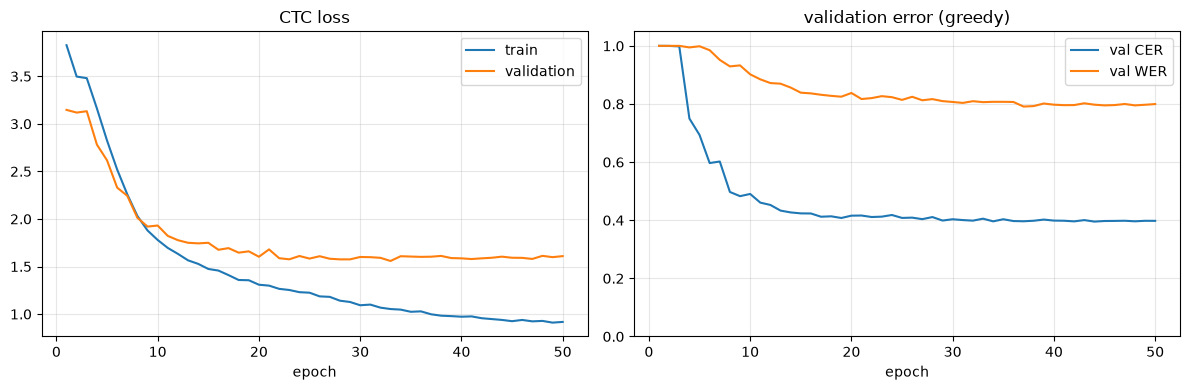

In [5]:
h = out["history"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="validation")
ax[0].set_title("CTC loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h.epoch, h.val_CER, label="val CER"); ax[1].plot(h.epoch, h.val_WER, label="val WER")
ax[1].set_ylim(0, 1.05); ax[1].set_title("validation error (greedy)"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(cfg["out"] / "figures" / f"{TAG}_training.png", dpi=150); plt.show()

## 5. Evaluate the best checkpoint on validation and test

In [6]:
model, res = T.evaluate_checkpoint(TAG, data, cfg)
r = T.save_result(TAG, HEAD, res, out, cfg, data)
print(pd.Series(r).to_string())

tag              transformer
head             transformer
down                       8
params               3142780
best_epoch                44
train_minutes          257.5
val_CER             0.395328
val_WER               0.7976
test_CER            0.268597
test_WER            0.693933
train_pages              361
val_pages                 87
test_pages                90


In [7]:
te = res["test"]["df"]
for lang, g in te.groupby("language"):
    print(f"{lang:8s} pages={len(g):3d}  CER={D.corpus_cer(g.reference, g.prediction):.4f}  WER={D.corpus_wer(g.reference, g.prediction):.4f}")

print()
order = te.sort_values("CER").reset_index(drop=True)
for name, i in [("BEST", 0), ("MEDIAN", len(order) // 2), ("WORST", len(order) - 1)]:
    row = order.iloc[i]
    print(f"--- {name}  ({row.id}, {row.language})  CER {row.CER:.3f}")
    print("reference :", row.reference[:200])
    print("prediction:", row.prediction[:200])

Hindi    pages= 49  CER=0.3108  WER=0.6890
Marathi  pages= 41  CER=0.2288  WER=0.7002

--- BEST  (ma_850_110173, Marathi)  CER 0.128
reference : कशामुळे आपलं लक्ष विचलित होऊ शकतं? सहसा ही मंडळी वरिष्ठ अनुभवी सदस्य असतात. मला आमच्यामध्ये असलेले मैत्रीपूर्ण संबंध खराब होऊ द्यायचे नव्हते. परिसर स्वच्छ करून ते आपल्या दिवसाची सुरुवात करतात. १४००१ प
prediction: कशामुळे आपंल लक्ष वियलित होऊ शकत? सह्सा ही मंडळी वरिषळ अनुभर्वी सदस्य आसातात. मला आमच्यामध्ये असलेले मैत्रपूर्ण संबंध खर होऊ हायाचे न्े. परिसर स्वच् करून ते आपल्या दिवसची सुरृवात करतात. ११४८०१ प्रमाणप
--- MEDIAN  (hi_153_14652, Hindi)  CER 0.251
reference : लक्ष्मण ने मेघनाद से युद्ध करके उसका वध कर दिया। कौन झूठे धर्मों का नाश करेगा? हमने तुम्हें सात'मसानी'का समूह यानी महान क़ुरआन दिया- लेकिन क्या परमेश्वर के दुश्मन जीत पाए? तू मेरी मदद कर ख़ुदा ने फरमा
prediction: लद्ण ने मेहनाद से चुद करसे उसका बला कर तदिया। कोंन झते धगो का नार करेगा? हमने तुम्े आात मसची। का रमह़ यानी महान कुरआन तिया- लेकि क्या परेस्तर के दुरसन जीत पाए? त गोरी मद क

**How to read the numbers.** CER = character errors / reference characters (0 = perfect, 1 = everything wrong, can exceed 1).
WER is the same on words and is always higher. What matters for the project is the *comparison between models* (notebook 04)
and that the result is honest (writer-disjoint test).